# Rapport de Projet : Définition d'un Soft-Sensor pour la Prédiction du RON

## 1. Introduction
L'objectif de ce projet est de développer un modèle de Machine Learning capable de prédire l'indice d'octane (RON) en temps réel à partir de variables de procédé (Température, Pression, Débit). Cela permet d'optimiser le raffinage sans attendre les analyses de laboratoire.

## 2. Exploration des données
Chargement, vérification des données manquantes et analyse statistique.

           Temp_C    Pres_bar    Flow_m3h   PNA_Ratio         RON    Quality
count  208.000000  208.000000  208.000000  208.000000  208.000000  19.000000
mean   543.873558    3.285096  131.106250    5.176442    9.064904   0.526316
std     31.144702    4.437752   23.292922   13.076271   27.449151   0.512989
min    501.700000    1.000000   85.900000    0.100000    0.000000   0.000000
25%    520.025000    1.200000  108.275000    0.600000    0.000000   0.000000
50%    527.700000    1.500000  145.700000    1.400000    0.000000   1.000000
75%    578.525000    3.000000  150.425000    1.600000    1.000000   1.000000
max    599.900000   23.100000  159.500000   49.600000   98.800000   1.000000


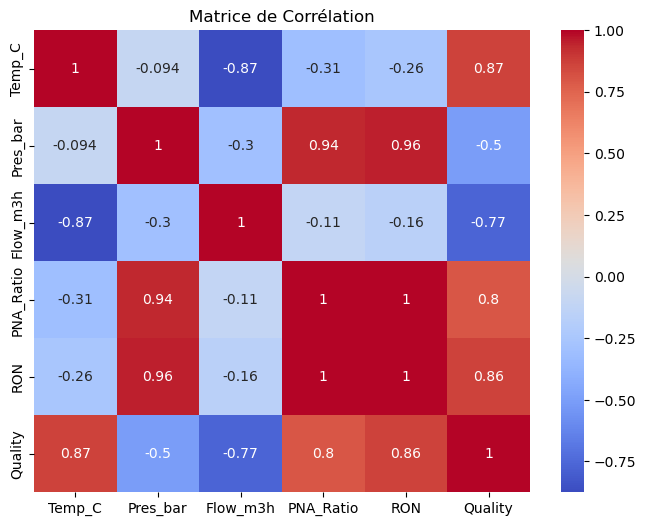

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score, classification_report, confusion_matrix

# Chargement et nettoyage
df = pd.read_csv('base_donnees_projet4.csv')
df = df[pd.to_numeric(df['Temp_C'], errors='coerce').notnull()]
df = df.apply(pd.to_numeric)
df['RON'] = df['RON'].fillna(df['RON'].mean())

# Statistiques et Corrélation
print(df.describe())
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Matrice de Corrélation")
plt.show()

## 3. Développement des modèles
### 3.1 Régression (Prédiction de la valeur RON)
### 3.2 Classification (Conformité de la qualité : RON >= 95)

In [7]:
# Préparation pour la régression
from sklearn.tree import plot_tree

X = df[['Temp_C', 'Pres_bar', 'Flow_m3h', 'PNA_Ratio']]
y_reg = df['RON']
X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)

reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

# Préparation pour la classification
y_class = (df['RON'] >= 95).astype(int)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_class, test_size=0.2, random_state=42)

dt_model = DecisionTreeClassifier(max_depth=3)
dt_model.fit(X_train_c, y_train_c)

DecisionTreeClassifier(max_depth=3)

## 4. Comparaison des modèles et Résultats

--- RÉSULTATS RÉGRESSION ---
RMSE: 1.0626
R2 Score: 0.9986

--- RÉSULTATS CLASSIFICATION (Arbre de Décision) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        39
           1       1.00      1.00      1.00         3

    accuracy                           1.00        42
   macro avg       1.00      1.00      1.00        42
weighted avg       1.00      1.00      1.00        42



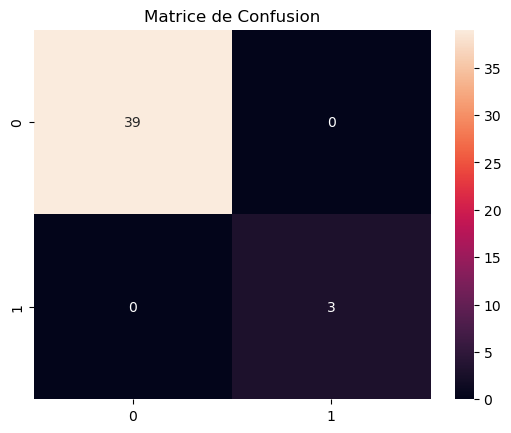

In [4]:
print("--- RÉSULTATS RÉGRESSION ---")
y_pred_reg = reg_model.predict(X_test)
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_reg)):.4f}")
print(f"R2 Score: {r2_score(y_test, y_pred_reg):.4f}")

print("\n--- RÉSULTATS CLASSIFICATION (Arbre de Décision) ---")
y_pred_class = dt_model.predict(X_test_c)
print(classification_report(y_test_c, y_pred_class))

# Matrice de confusion
sns.heatmap(confusion_matrix(y_test_c, y_pred_class), annot=True, fmt='d')
plt.title("Matrice de Confusion")
plt.show()

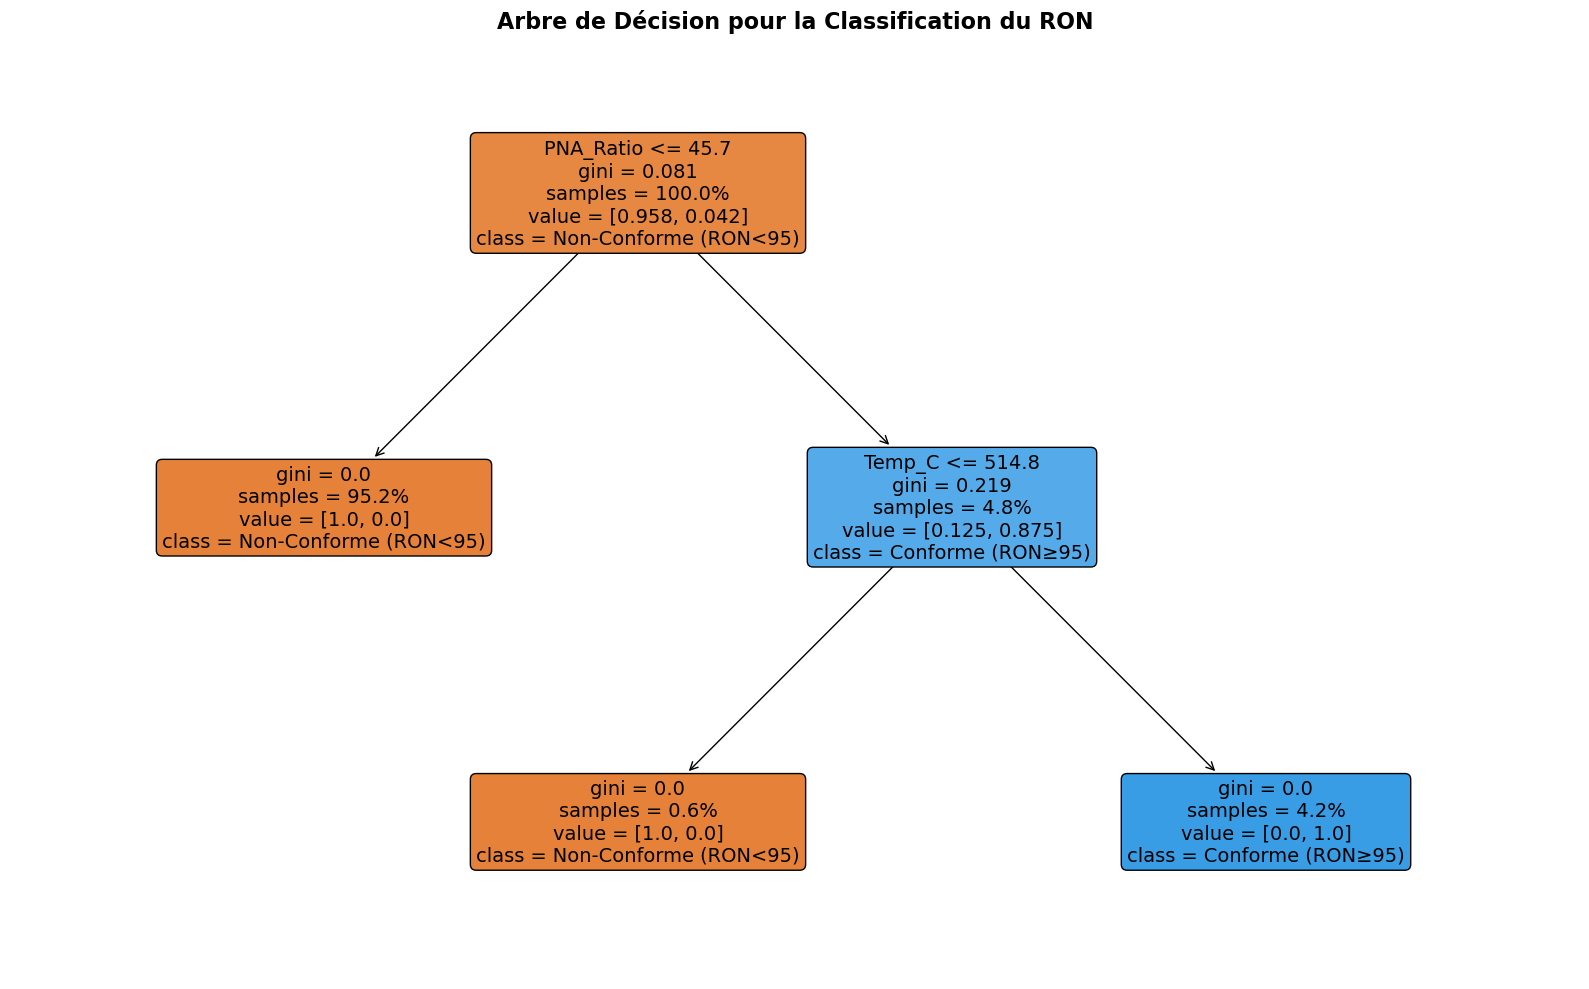

In [10]:
# Affichage de l'arbre de décision
plt.figure(figsize=(16, 10))
plot_tree(dt_model, 
          feature_names=list(X.columns), 
          class_names=['Non-Conforme (RON<95)', 'Conforme (RON≥95)'], 
          filled=True,
          rounded=True,
          fontsize=14,
          proportion=True)
plt.title("Arbre de Décision pour la Classification du RON", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Analyse de l'impact industriel
Interprétation des résultats pour le contrôle du procédé.

In [11]:
new_sample = pd.DataFrame([[510, 15, 120, 45]], columns=X.columns)
ron_val = reg_model.predict(new_sample)[0]
print(f"RON prédit : {ron_val:.2f}")

if ron_val < 95:
    print("Impact : Produit non-conforme. Action : Augmenter la Température de réaction.")
else:
    print("Impact : Produit conforme. Maintenir les paramètres.")

RON prédit : 92.30
Impact : Produit non-conforme. Action : Augmenter la Température de réaction.


## 6. Conclusion générale
Le modèle de régression fournit une estimation précise du RON, tandis que la classification permet une alerte rapide sur la conformité de la production.